# 02 · Member segmentation and the offer funnel

Built on the dbt marts (`marts.dim_member`, `marts.mart_member_rfm`, `marts.fct_member_campaign`), so every number here can be reproduced in SQL or a BI tool.

Questions:
1. Which member segments drive value, and how do they shop?
2. How do members move through the offer funnel: targeted → shopped → bought an offer product → redeemed?
3. Who redeems, and is redemption a good measure of offer success?

In [1]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from nectar.config import WAREHOUSE_PATH
from nectar import viz
from nectar.viz import BLUE, GREY, TEXT_2

viz.set_style()
pd.set_option("display.float_format", "{:,.2f}".format)
con = duckdb.connect(str(WAREHOUSE_PATH), read_only=True)
q = lambda sql: con.sql(sql).df()

## 1. RFM segments

RFM covers the last 52 weeks of data (days 348–711). Each member gets a 1–5 score on **R**ecency, **F**requency (trips) and **M**onetary value (spend), using percentile ranks so that tied members share a score. Segments come from recency against the average of the F and M scores; the rules live in `dbt/models/marts/mart_member_rfm.sql`.

In [2]:
seg_order = ["Champions", "Loyal", "At risk", "Potential loyalists", "Needs attention",
             "Hibernating", "About to sleep", "Recent, low value", "Lost"]
seg = q('''
SELECT r.segment,
       COUNT(*)                              AS members,
       SUM(r.monetary)                       AS spend_52w,
       MEDIAN(r.recency_days)                AS median_recency_days,
       MEDIAN(r.frequency)                   AS median_trips_52w,
       MEDIAN(m.median_basket_value)         AS median_basket,
       MEDIAN(m.member_discount_rate)        AS median_member_discount_rate,
       AVG(m.ever_targeted::INT)             AS share_ever_targeted
FROM marts.mart_member_rfm r JOIN marts.dim_member m USING (member_id)
GROUP BY 1
''').set_index("segment").loc[seg_order]
seg["share_members"] = seg.members / seg.members.sum()
seg["share_spend"] = seg.spend_52w / seg.spend_52w.sum()
seg[["members", "share_members", "share_spend", "median_recency_days", "median_trips_52w",
     "median_basket", "median_member_discount_rate", "share_ever_targeted"]]

,members,share_members,share_spend,median_recency_days,median_trips_52w,median_basket,median_member_discount_rate,share_ever_targeted
segment,,,,,,,,
Champions,652,0.26,0.50,1.00,92.00,18.77,0.15,0.96
Loyal,287,0.11,0.20,6.00,72.00,23.99,0.14,0.94
At risk,190,0.08,0.10,18.00,58.00,22.30,0.15,0.92
Potential loyalists,260,0.10,0.05,1.00,29.00,16.56,0.16,0.49
Needs attention,230,0.09,0.05,6.00,30.00,16.61,0.15,0.53
Hibernating,344,0.14,0.05,16.00,22.00,17.69,0.16,0.38
About to sleep,43,0.02,0.00,6.00,9.00,12.96,0.14,0.12
"Recent, low value",28,0.01,0.00,0.00,8.00,10.94,0.15,0.11
Lost,466,0.19,0.04,66.00,10.00,16.44,0.15,0.27


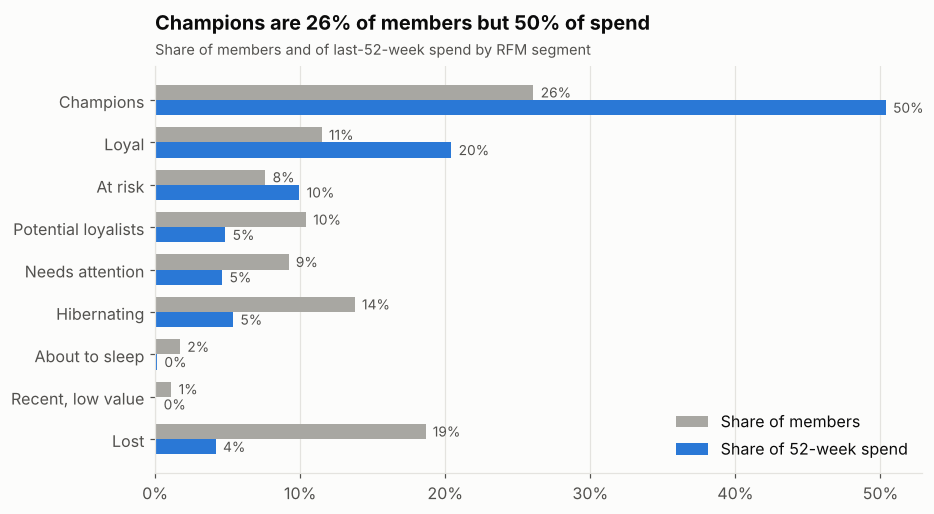

In [3]:
plot = seg.iloc[::-1]
y = np.arange(len(plot))
h = 0.36
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(y + h / 2, plot.share_members, height=h, color=GREY, label="Share of members")
ax.barh(y - h / 2, plot.share_spend, height=h, color=BLUE, label="Share of 52-week spend")
for yi, (sm, ss) in enumerate(zip(plot.share_members, plot.share_spend)):
    ax.text(sm + 0.005, yi + h / 2, f"{sm:.0%}", va="center", fontsize=9, color=TEXT_2)
    ax.text(ss + 0.005, yi - h / 2, f"{ss:.0%}", va="center", fontsize=9, color=TEXT_2)
ax.set_yticks(y, plot.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.grid(axis="y", visible=False); ax.grid(axis="x")
champ = seg.loc["Champions"]
ax.set_title(f"Champions are {champ.share_members:.0%} of members but {champ.share_spend:.0%} of spend")
viz.subtitle(ax, "Share of members and of last-52-week spend by RFM segment")
ax.legend(loc="lower right")
viz.save(fig, "07_segment_value"); fig

In [4]:
at_risk = seg.loc["At risk"]
print(f"'At risk' members: {at_risk.members:,.0f} ({at_risk.share_members:.0%}), "
      f"{at_risk.share_spend:.0%} of spend, median {at_risk.median_recency_days:.0f} days since last trip.")

'At risk' members: 190 (8%), 10% of spend, median 18 days since last trip.


**Reading the segments**

- **Champions and Loyal** make up about 38% of members and 71% of spend. Blanket offers to them are expensive, because many would buy anyway. This is where uplift targeting saves the most margin.
- **At risk** members spent heavily but their median gap since the last trip is 18 days, against 1 day for Champions. They are the obvious target for win-back offers.
- **Lost / Hibernating** members are cheap to reach, but their value is small and uncertain.

## 2. The offer funnel

`fct_member_campaign` has one row per (member, campaign) for every member who was targeted by the campaign or shopped during its window.

In [5]:
funnel = q('''
SELECT COUNT(*)                                        AS targeted,
       SUM(shopped_in_window::INT)                     AS shopped_in_window,
       SUM(bought_offer_product::INT)                  AS bought_offer_product,
       SUM(redeemed::INT)                              AS redeemed
FROM marts.fct_member_campaign WHERE is_targeted
''').T.rename(columns={0: "member_campaigns"})
funnel["share_of_targeted"] = funnel.member_campaigns / funnel.member_campaigns.iloc[0]
funnel["step_conversion"] = funnel.member_campaigns / funnel.member_campaigns.shift(1)
funnel

,member_campaigns,share_of_targeted,step_conversion
targeted,"7,208.00",1.00,NaN
shopped_in_window,"7,043.00",0.98,0.98
bought_offer_product,"5,579.00",0.77,0.79
redeemed,889.00,0.12,0.16


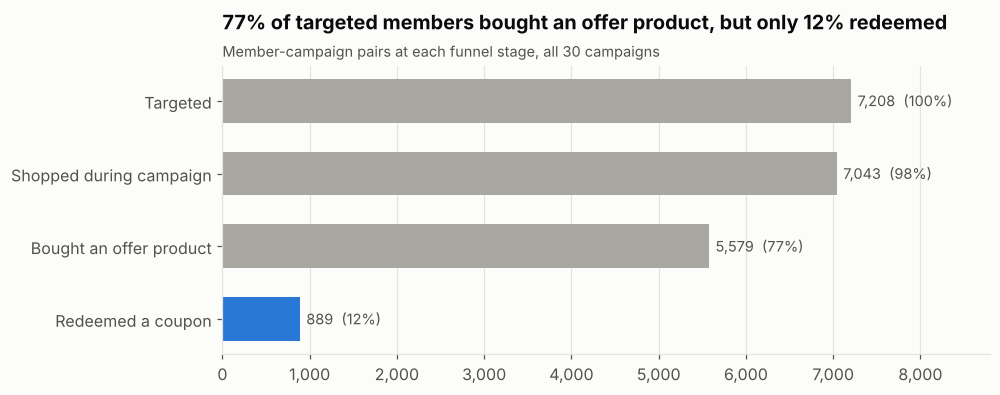

In [6]:
labels = ["Targeted", "Shopped during campaign", "Bought an offer product", "Redeemed a coupon"]
vals = funnel.member_campaigns.values
shares = funnel.share_of_targeted.values
fig, ax = plt.subplots(figsize=(9, 3.4))
y = np.arange(len(vals))[::-1]
ax.barh(y, vals, color=[GREY, GREY, GREY, BLUE], height=0.6)
for yi, v, s in zip(y, vals, shares):
    ax.text(v + vals[0] * 0.01, yi, f"{v:,.0f}  ({s:.0%})", va="center", fontsize=9.5, color=TEXT_2)
ax.set_yticks(y, labels)
ax.set_xlim(0, vals[0] * 1.22)
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", visible=False); ax.grid(axis="x")
ax.set_title(f"{shares[2]:.0%} of targeted members bought an offer product, but only {shares[3]:.0%} redeemed")
viz.subtitle(ax, "Member-campaign pairs at each funnel stage, all 30 campaigns")
viz.save(fig, "08_offer_funnel"); fig

## 3. Does redemption measure success?

If most targeted members buy offer products *without* redeeming, then many would have bought anyway. The comparison below shows how often members who were **not** targeted bought the same offer products during the same campaign window.

*Caveat:* targeted and non-targeted members differ (see notebook 01), so this is descriptive, not causal.

In [7]:
by_type = q('''
SELECT campaign_type,
       AVG(bought_offer_product::INT) FILTER (WHERE is_targeted AND shopped_in_window)     AS targeted_bought,
       AVG(bought_offer_product::INT) FILTER (WHERE NOT is_targeted)                       AS not_targeted_bought,
       AVG(redeemed::INT)             FILTER (WHERE is_targeted AND shopped_in_window)     AS targeted_redeemed,
       COUNT(*) FILTER (WHERE is_targeted)                                                 AS targeted_pairs,
       COUNT(*) FILTER (WHERE NOT is_targeted)                                             AS not_targeted_pairs
FROM marts.fct_member_campaign GROUP BY 1 ORDER BY 1
''').set_index("campaign_type")
by_type

,targeted_bought,not_targeted_bought,targeted_redeemed,targeted_pairs,not_targeted_pairs
campaign_type,,,,,
TypeA,0.97,0.84,0.16,3979,6885
TypeB,0.56,0.26,0.08,2655,37056
TypeC,0.63,0.23,0.08,574,12799


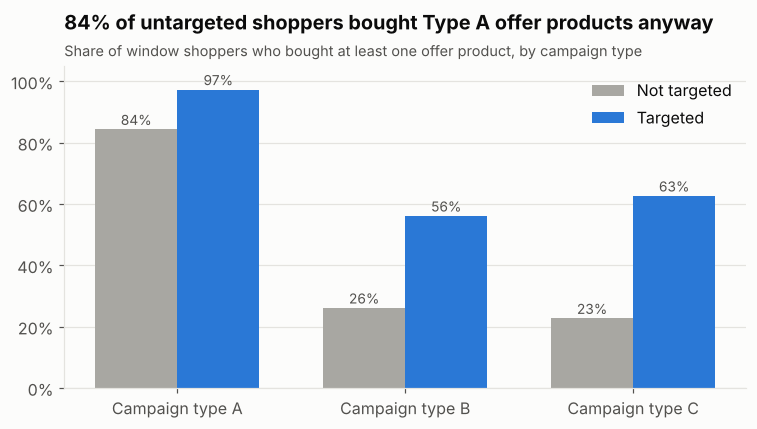

In [8]:
x = np.arange(len(by_type))
w = 0.36
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(x - w / 2, by_type.not_targeted_bought, width=w, color=GREY, label="Not targeted")
ax.bar(x + w / 2, by_type.targeted_bought, width=w, color=BLUE, label="Targeted")
for xi, (a, b) in enumerate(zip(by_type.not_targeted_bought, by_type.targeted_bought)):
    ax.text(xi - w / 2, a + 0.015, f"{a:.0%}", ha="center", fontsize=9, color=TEXT_2)
    ax.text(xi + w / 2, b + 0.015, f"{b:.0%}", ha="center", fontsize=9, color=TEXT_2)
ax.set_xticks(x, [f"Campaign type {t[-1]}" for t in by_type.index])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_ylim(0, 1.05)
a = by_type.loc["TypeA"]
ax.set_title(f"{a.not_targeted_bought:.0%} of untargeted shoppers bought Type A offer products anyway")
viz.subtitle(ax, "Share of window shoppers who bought at least one offer product, by campaign type")
ax.legend(loc="upper right")
viz.save(fig, "09_bought_anyway"); fig

### Who redeems?

To avoid using the future to explain the past, members are grouped by **weekly spend before any campaign** (days 113–223), not by their later RFM segment.

In [9]:
resp = q('''
WITH pre AS (
    SELECT member_id, SUM(basket_value) / 16.0 AS pre_weekly_spend
    FROM marts.fct_basket WHERE day BETWEEN 113 AND 223 GROUP BY 1
)
SELECT f.member_id, f.redeemed, f.bought_offer_product, p.pre_weekly_spend
FROM marts.fct_member_campaign f JOIN pre p USING (member_id)
WHERE f.is_targeted
''')
resp["spend_quintile"] = pd.qcut(resp.pre_weekly_spend, 5, labels=["Q1 low", "Q2", "Q3", "Q4", "Q5 high"])
by_q = resp.groupby("spend_quintile", observed=True).agg(
    pairs=("redeemed", "size"),
    redemption_rate=("redeemed", "mean"),
    bought_offer_product=("bought_offer_product", "mean"),
    median_pre_weekly_spend=("pre_weekly_spend", "median"),
)
by_q

,pairs,redemption_rate,bought_offer_product,median_pre_weekly_spend
spend_quintile,,,,
Q1 low,1435,0.08,0.74,13.37
Q2,1431,0.08,0.79,28.82
Q3,1430,0.14,0.78,44.68
Q4,1434,0.15,0.77,65.88
Q5 high,1429,0.17,0.79,111.12


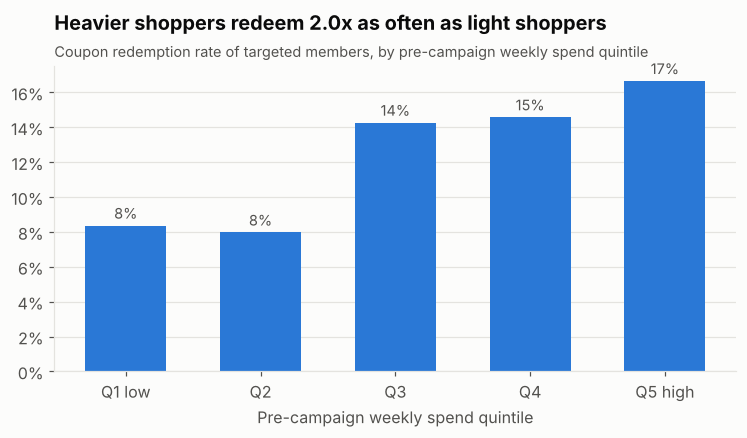

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(by_q.index.astype(str), by_q.redemption_rate, color=BLUE, width=0.6)
for xi, v in enumerate(by_q.redemption_rate):
    ax.text(xi, v + 0.004, f"{v:.0%}", ha="center", fontsize=9.5, color=TEXT_2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
lo, hi = by_q.redemption_rate.iloc[0], by_q.redemption_rate.iloc[-1]
ax.set_title(f"Heavier shoppers redeem {hi / lo:.1f}x as often as light shoppers")
viz.subtitle(ax, "Coupon redemption rate of targeted members, by pre-campaign weekly spend quintile")
ax.set_xlabel("Pre-campaign weekly spend quintile")
viz.save(fig, "10_redemption_by_spend"); fig

## Summary

| # | Finding | Implication |
|---|---|---|
| 1 | Champions + Loyal ≈ 38% of members, ≈ 71% of 52-week spend | Blanket offers to them leak margin; uplift targeting matters most here |
| 2 | "At risk" members: high past value, median 18 days since last trip | A natural win-back audience for retention offers |
| 3 | 77% of targeted members bought an offer product, but only 12% redeemed | Purchase of promoted products is mostly not driven by the coupon |
| 4 | Many untargeted shoppers bought offer products anyway (84% for Type A) | Redemption rate and "bought offer product" overstate offer impact |
| 5 | Redemption rises steeply with pre-campaign spend | Redeemers are mainly heavy shoppers; a propensity model will chase them |

**Conclusion:** redemption measures *who uses coupons*, not *who changes behaviour*. That is the case for the randomised simulator (week 3) and for uplift models (weeks 5–6), which target incremental response instead.